In [1]:
import sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')   # shared folder: holds project_utils.py + torch_models.py
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Mounted at /content/drive


In [2]:
import json
from project_utils import URL_FEATURES, load_master, get_feature_splits, evaluate_model, log_result, plot_history
from torch_models import fit_mlp, predict_proba, count_params, DEVICE

print('Running on', DEVICE)
df = load_master(DATA_DIR)
data, _ = get_feature_splits(df, URL_FEATURES, split_col='split')
X_val, y_val = data['val']

Running on cpu


In [3]:
model, history, cfg = fit_mlp(data, {'hidden': (64, 32), 'dropout': 0.0})
print(model)
print('Trainable parameters:', count_params(model))
json.dump(history, open(DATA_DIR / 'history_mlp_url.json', 'w'))

Epoch  1  train loss 0.04958  val loss 0.00311
Epoch  2  train loss 0.00165  val loss 0.00223
Epoch  3  train loss 0.00116  val loss 0.00186
Epoch  4  train loss 0.00097  val loss 0.00181
Epoch  5  train loss 0.00093  val loss 0.00173
Epoch  6  train loss 0.00083  val loss 0.00188
Epoch  7  train loss 0.00083  val loss 0.00181
Epoch  8  train loss 0.00081  val loss 0.00174
Early stopping: no improvement for 3 epochs.
MLP(
  (body): Sequential(
    (0): Linear(in_features=22, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (out): Linear(in_features=32, out_features=1, bias=True)
)
Trainable parameters: 3585


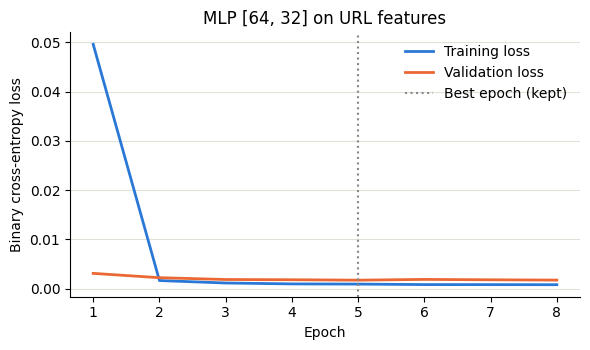

In [5]:
plot_history(history, 'MLP [64, 32] on URL features', FIG_DIR / 'loss_mlp_url.png')

Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
  MLP   val    0.9997        1.0  0.9994 0.9997   0.9999  0.9999                0                9


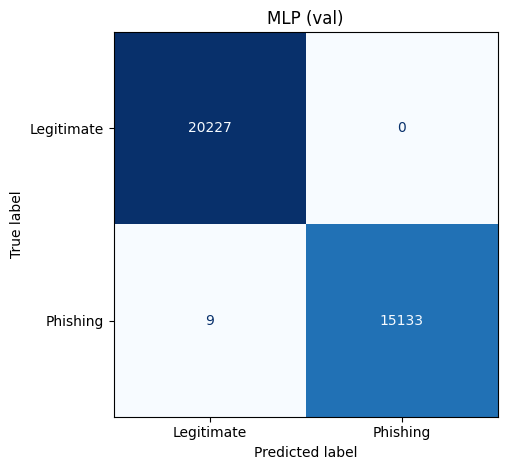

In [7]:
res = evaluate_model('MLP', 'val', y_val, predict_proba(model, X_val), save_path=FIG_DIR / 'cm_mlp_url_val.png')
log_result(res, {'family': 'MLP', 'experiment': 'main', 'features': 'url22', 'split_col': 'split',
                 'params': count_params(model), 'best_epoch': history['best_epoch'], **cfg}, LOG)